In [1]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Paleta INF672
INDIGO = "#4F46E5"
PURPURA = "#7E22CE"
CORAL = "#F43F5E"
TINTA = "#111827"

# Estilo global de Matplotlib
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["font.size"] = 11
plt.rcParams["axes.edgecolor"] = "#9CA3AF"

print("Entorno listo ✓")

Entorno listo ✓


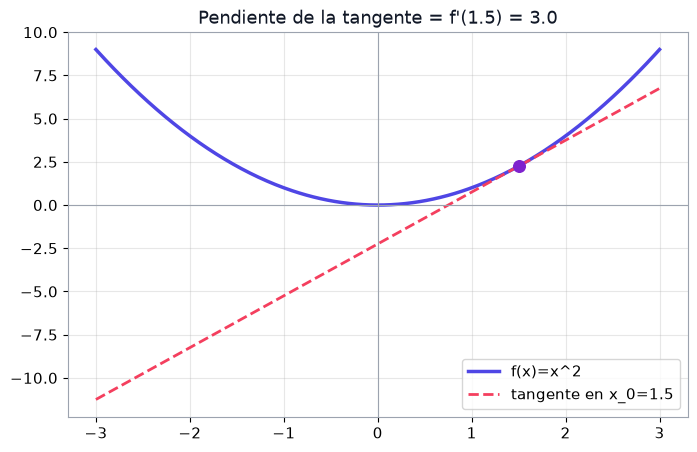

In [2]:
f = lambda x: x**2  # función
fp = lambda x: 2 * x  # derivada : f'(x)=2x
x0 = 1.5

x = np.linspace(-3, 3, 400)  #
tangente = f(x0) + fp(x0) * (x - x0)  # recta: y = f(x0) + f'(x0)(x - x0)

plt.plot(x, f(x), color=INDIGO, lw=2.5, label=r"f(x)=x^2")  #
plt.plot(
    x,
    tangente,
    color=CORAL,
    lw=2,
    ls="--",
    label=fr"tangente en x_0={x0}",
)  #
plt.scatter([x0], [f(x0)], color=PURPURA, s=70, zorder=5)  #
plt.axhline(0, color="#9CA3AF", lw=0.8)  #
plt.axvline(0, color="#9CA3AF", lw=0.8)  #
plt.title(
    f"Pendiente de la tangente = f'({x0}) = {fp(x0)}", color=TINTA
)  #
plt.legend()
plt.show()

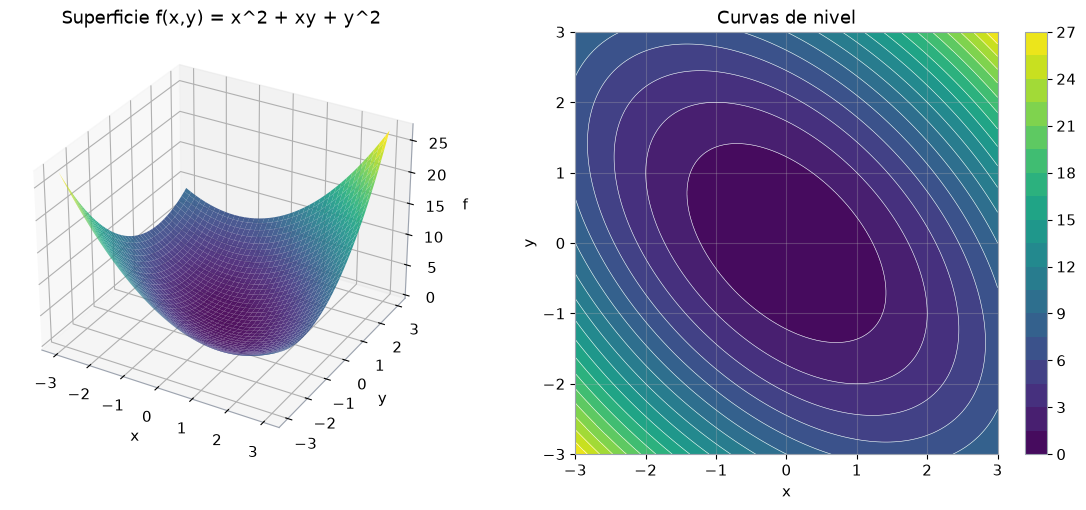

In [3]:
f2 = lambda x, y: x**2 + x * y + y**2  #

x = np.linspace(-3, 3, 120)  #
y = np.linspace(-3, 3, 120)  #
X, Y = np.meshgrid(x, y)  #
Z = f2(X, Y) 

fig = plt.figure(figsize=(12, 5))  

# Subplot 3D
ax1 = fig.add_subplot(1, 2, 1, projection="3d")  
ax1.plot_surface(X, Y, Z, cmap="viridis", alpha=0.92)  
ax1.set_title("Superficie f(x,y) = x^2 + xy + y^2")  
ax1.set_xlabel("x")  
ax1.set_ylabel("y")  
ax1.set_zlabel("f")  

# Subplot Curvas de Nivel
ax2 = fig.add_subplot(1, 2, 2)  
cs = ax2.contourf(X, Y, Z, levels=20, cmap="viridis") 
ax2.contour(X, Y, Z, levels=20, colors="white", linewidths=0.4)  
ax2.set_title("Curvas de nivel")  
ax2.set_xlabel("x")  
ax2.set_ylabel("y")  
ax2.set_aspect("equal")  
fig.colorbar(cs, ax=ax2)  

plt.tight_layout()  
plt.show()

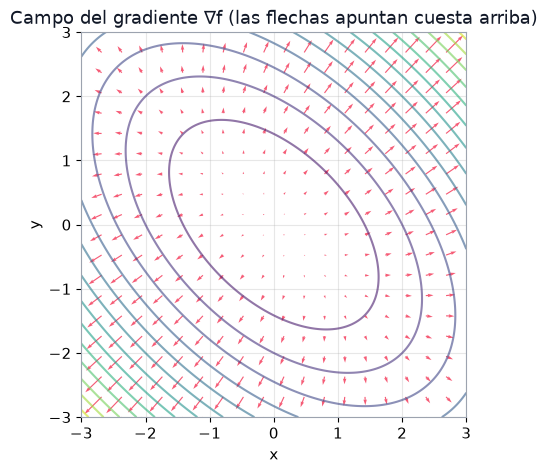

In [4]:
def grad_f2(x, y):  # Gradiente obtenido A MANO:  f = (2x+y, x+2y)
  return 2 * x + y, x + 2 * y  #


# Malla dispersa para las flechas
xg = np.linspace(-3, 3, 20)  #
yg = np.linspace(-3, 3, 20)  #
Xg, Yg = np.meshgrid(xg, yg)  #
U, V = grad_f2(Xg, Yg)  #

# Malla fina para las curvas de fondo
xf = np.linspace(-3, 3, 200)  #
yf = np.linspace(-3, 3, 200)  #
Xf, Yf = np.meshgrid(xf, yf)  #
Zf = f2(Xf, Yf)  #

plt.contour(Xf, Yf, Zf, levels=15, cmap="viridis", alpha=0.6)  #
plt.quiver(Xg, Yg, U, V, color=CORAL, alpha=0.85)  #
plt.title(
    "Campo del gradiente ∇f (las flechas apuntan cuesta arriba)", color=TINTA
)  #
plt.xlabel("x")  #
plt.ylabel("y")  #
plt.gca().set_aspect("equal")  #
plt.show()

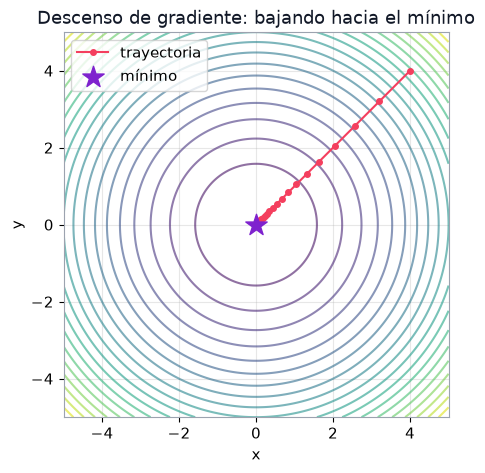

In [5]:
# CÁLCULO DE LA TRAYECTORIA
f3 = lambda x, y: x**2 + y**2  #
grad_f3 = lambda x, y: np.array([2 * x, 2 * y])  #  f = (2x, 2y)

punto = np.array([4.0, 4.0])  # x_0
alpha = 0.1  # Tasa de aprendizaje
trayectoria = [punto.copy()]  #

for _ in range(25):  #
  punto = punto - alpha * grad_f3(*punto)  # regla de actualizacion
  trayectoria.append(punto.copy())  #

trayectoria = np.array(trayectoria)  #

# GRAFICACIÓN DE LA TRAYECTORIA
xf = np.linspace(-5, 5, 200)  #
yf = np.linspace(-5, 5, 200)  #
Xf, Yf = np.meshgrid(xf, yf)  #
Zf = f3(Xf, Yf)  #

plt.contour(Xf, Yf, Zf, levels=20, cmap="viridis", alpha=0.6)  #
plt.plot(
    trayectoria[:, 0],
    trayectoria[:, 1],
    "o-",
    color=CORAL,
    ms=4,
    lw=1.5,
    label="trayectoria",
)  #
plt.scatter(
    [0], [0], marker="*", s=260, color=PURPURA, zorder=5, label="mínimo"
)  #
plt.title(
    "Descenso de gradiente: bajando hacia el mínimo", color=TINTA
)  #
plt.xlabel("x")  #
plt.ylabel("y")  #
plt.legend()  #
plt.gca().set_aspect("equal")  #
plt.show()

Visualización 1 (Recta tangente): Se evaluó f(x)=x^2 y su derivada f'(x)=2x en x_0=1.5. La tangente en el punto (1.5, 2.25) tiene una pendiente m=3.0, confirmando que la derivada describe la tasa de cambio instantánea.
Visualización 2 (Superficie y niveles): La función np.meshgrid construye la cuadrícula para calcular Z = x^2+xy+y^2. En 2D, las curvas de nivel forman elipses inclinadas asociadas a valores constantes de elevación.
Visualización 3 (Campo de gradiente): El vector f = (2x+y, x+2y) apunta hacia la dirección de mayor elevación y resulta perpendicular a cada curva de nivel en todo el plano.
Visualización 4 (Descenso de gradiente): Al avanzar progresivamente hacia -f, los pasos iniciales son más largos por la magnitud del gradiente y se reducen automáticamente conforme se aproxima al origen (0,0).

E2: Tangente para g(x) = x^3 - 3x en x_0 = 1
Derivada analítica a mano: g'(x) = 3x^2 - 3. Evaluando en x_0 = 1, obtenemos g(1) = -2 y pendiente g'(1) = 3(1)^2 - 3 = 0.

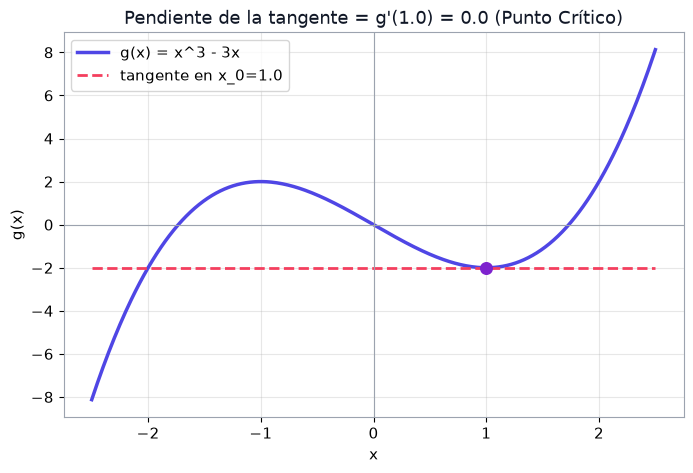

In [6]:
g = lambda x: x**3 - 3 * x
gp = lambda x: 3 * x**2 - 3
x0 = 1.0

x = np.linspace(-2.5, 2.5, 400)
tangente = g(x0) + gp(x0) * (x - x0)

plt.plot(x, g(x), color=INDIGO, lw=2.5, label=r"g(x) = x^3 - 3x")
plt.plot(
    x,
    tangente,
    color=CORAL,
    lw=2,
    ls="--",
    label=fr"tangente en x_0={x0}",
)
plt.scatter([x0], [g(x0)], color=PURPURA, s=70, zorder=5)
plt.axhline(0, color="#9CA3AF", lw=0.8)
plt.axvline(0, color="#9CA3AF", lw=0.8)
plt.title(
    f"Pendiente de la tangente = g'({x0}) = {gp(x0)} (Punto Crítico)",
    color=TINTA,
)
plt.xlabel("x")
plt.ylabel("g(x)")
plt.legend()
plt.show()

E3. Descenso de Gradiente desde (-4, 3)

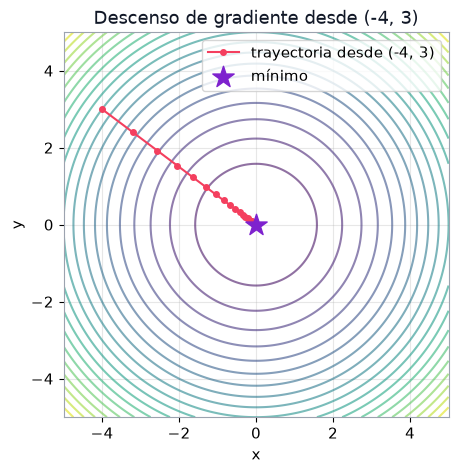

In [7]:
f3 = lambda x, y: x**2 + y**2
grad_f3 = lambda x, y: np.array([2 * x, 2 * y])

punto = np.array([-4.0, 3.0])  # Nuevo punto inicial E3
alpha = 0.1
trayectoria = [punto.copy()]

for _ in range(25):
  punto = punto - alpha * grad_f3(*punto)
  trayectoria.append(punto.copy())

trayectoria = np.array(trayectoria)

xf = np.linspace(-5, 5, 200)
yf = np.linspace(-5, 5, 200)
Xf, Yf = np.meshgrid(xf, yf)
Zf = f3(Xf, Yf)

plt.contour(Xf, Yf, Zf, levels=20, cmap="viridis", alpha=0.6)
plt.plot(
    trayectoria[:, 0],
    trayectoria[:, 1],
    "o-",
    color=CORAL,
    ms=4,
    lw=1.5,
    label="trayectoria desde (-4, 3)",
)
plt.scatter([0], [0], marker="*", s=260, color=PURPURA, zorder=5, label="mínimo")
plt.title("Descenso de gradiente desde (-4, 3)", color=TINTA)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.gca().set_aspect("equal")
plt.show()

Al iniciar en (-4, 3), la trayectoria se desplaza radialmente desde el cuadrante II en dirección recta hacia el mínimo global (0,0). La simetría parabólica de la función f(x,y)=x^2+y^2 garantiza que la ruta apunte al origen independientemente del punto inicial seleccionado.

E4. ¿Cómo sabe un modelo hacia qué lado mover cada parámetro para reducir el error?
El modelo determina la dirección mediante el cálculo del vector gradiente de la función de pérdida respecto a cada uno de sus parámetros (pesos w y sesgo b). Como el gradiente apunta en la dirección donde el error se incrementa con mayor rapidez, el algoritmo de optimización actualiza los parámetros en la dirección opuesta